# Вероятностная оценка Тіл Mix
Учебный календарь начинается 7 сентября 2026 года. Прогноз остатка на 15 ноября сравнивает 10 открытых историй с вариантами из 4, 5 и 8. Входные данные с GitHub сохранены в `throughput-reference.json`. Одна единица — закрытое как completed issue, pull requests и иные причины закрытия исключены. Числа внешнего проекта используются для сравнения и калибровки допущения, а скорость Тіл Mix требуется измерить отдельно.

In [1]:
from collections import Counter
from datetime import date, timedelta
from math import ceil
from pathlib import Path
from random import Random
from statistics import mean
import json

reference_path = Path("throughput-reference.json")
if not reference_path.exists():
    reference_path = Path("course") / reference_path
reference = json.loads(reference_path.read_text(encoding="utf-8"))
from_day = date.fromisoformat(reference["from_inclusive"])
until_day = date.fromisoformat(reference["to_exclusive"])
assert (until_day - from_day).days % 7 == 0
historic_weeks = (until_day - from_day).days // 7
closed_days = Counter(date.fromisoformat(item["closed_at"][:10]) for item in reference["issues"])
assert all(from_day <= day < until_day for day in closed_days)
assert len({item["issue"] for item in reference["issues"]}) == sum(closed_days.values())

# Отдельный сценарий ограничивает влияние пакетных закрытий.
batch_limit = 20
batch_days = {day: count for day, count in closed_days.items() if count > batch_limit}

def weekly_totals(excluded_days):
    return [
        sum(
            count for day, count in closed_days.items()
            if day not in excluded_days and (day - from_day).days // 7 == week
        )
        for week in range(historic_weeks)
    ]

raw = weekly_totals(set())
clean = weekly_totals(batch_days)
print("Raw weekly closures:", raw)
print("Adjusted weekly closures:", clean)
print("Raw and adjusted means:", round(mean(raw), 2), round(mean(clean), 2))
print("Batch closure dates:", {day.isoformat(): count for day, count in sorted(batch_days.items())})
assert sum(raw) - sum(clean) == sum(batch_days.values())

Raw weekly closures: [3, 3, 0, 1, 5, 4, 1, 142, 1, 2, 1, 2, 0, 2]
Adjusted weekly closures: [3, 3, 0, 1, 5, 4, 1, 3, 1, 2, 1, 2, 0, 2]
Raw and adjusted means: 11.93 2
Batch closure dates: {'2026-09-26': 50, '2026-09-27': 89}


## Симуляция
В каждом прогоне каждую неделю выбираем один исторический объём с возвращением. В соло-сценарии распределение дополнительно прореживается: каждая единица выбранного объёма учитывается с вероятностью 0,70. Это предположение о меньшей пропускной способности одного человека. Падение до 0,50 проверяем отдельно. Прогон заканчивается в конце недели, когда суммарный объём впервые покрывает весь срез. Нулевые недели участвуют в выборке.

In [2]:
TRIALS = 10_000
SEED = 6_152_026
first_week = date(2026, 11, 16)
review_week = 5
quantiles = (.50, .70, .85, .95)

def simulate(history, total_items, retention, trials=TRIALS, seed=SEED):
    if not history or max(history) == 0 or total_items <= 0 or not (0 < retention <= 1):
        raise ValueError("Simulation needs a positive backlog and non-zero throughput")
    rng = Random(seed)
    outcomes = []
    for _ in range(trials):
        weeks = 0
        remaining = total_items
        while remaining > 0:
            drawn = rng.choice(history)
            delivered = drawn if retention == 1 else sum(rng.random() < retention for _ in range(drawn))
            remaining -= delivered
            weeks += 1
        outcomes.append(weeks)
    return sorted(outcomes)


def percentile(outcomes, share):
    return outcomes[ceil(len(outcomes) * share) - 1]


def probability_by(outcomes, week):
    return sum(value <= week for value in outcomes) / len(outcomes)


def week_end(weeks):
    return first_week + timedelta(days=7 * weeks - 1)


scenarios = {
    "Сырые данные, 10": simulate(raw, 10, 1),
    "Без всплеска, 10": simulate(clean, 10, 1),
    "Соло 0,70, 10": simulate(clean, 10, .70),
    "Соло 0,70, 8": simulate(clean, 8, .70),
    "Соло 0,70, 5": simulate(clean, 5, .70),
    "Соло 0,70, 4": simulate(clean, 4, .70),
    "Соло 0,50, 10": simulate(clean, 10, .50)
}
for name, outcomes in scenarios.items():
    points = [percentile(outcomes, q) for q in quantiles]
    dates = ", ".join(f"P{int(q * 100)}={week_end(w):%d.%m.%Y}" for q, w in zip(quantiles, points))
    print(f"{name:<18} {points} нед. | {dates} | к {week_end(review_week):%d.%m}: {probability_by(outcomes, review_week):.2%}")
print(f"Вероятность завершить за неделю — сырые {probability_by(scenarios['Сырые данные, 10'], 1):.2%}, очищенные {probability_by(scenarios['Без всплеска, 10'], 1):.2%}")
assert all(len(outcomes) == TRIALS for outcomes in scenarios.values())
assert [percentile(scenarios["Соло 0,70, 10"], q) for q in quantiles] == [7, 9, 10, 12]

Сырые данные, 10   [5, 6, 7, 8] нед. | P50=20.12.2026, P70=27.12.2026, P85=03.01.2027, P95=10.01.2027 | к 20.12: 64.71%
Без всплеска, 10   [5, 6, 7, 8] нед. | P50=20.12.2026, P70=27.12.2026, P85=03.01.2027, P95=10.01.2027 | к 20.12: 54.23%
Соло 0,70, 10      [7, 9, 10, 12] нед. | P50=03.01.2027, P70=17.01.2027, P85=24.01.2027, P95=07.02.2027 | к 20.12: 17.35%
Соло 0,70, 8       [6, 7, 8, 10] нед. | P50=27.12.2026, P70=03.01.2027, P85=10.01.2027, P95=24.01.2027 | к 20.12: 39.97%
Соло 0,70, 5       [4, 5, 6, 7] нед. | P50=13.12.2026, P70=20.12.2026, P85=27.12.2026, P95=03.01.2027 | к 20.12: 82.37%
Соло 0,70, 4       [3, 4, 5, 6] нед. | P50=06.12.2026, P70=13.12.2026, P85=20.12.2026, P95=27.12.2026 | к 20.12: 91.21%
Соло 0,50, 10      [10, 12, 14, 16] нед. | P50=24.01.2027, P70=07.02.2027, P85=21.02.2027, P95=07.03.2027 | к 20.12: 3.15%
Вероятность завершить за неделю — сырые 7.40%, очищенные 0.00%


## Гистограмма и кумулятивная кривая
На левой панели частота сроков для 10 историй. На правой накопленная вероятность для четырёх и десяти историй. 20 декабря заканчивается неделя 15. Ось отсчитывает недели с 16 ноября, начала оставшегося периода. Поздний ответ эксперта или заказчика и изменения состава бэклога меняют прогноз.

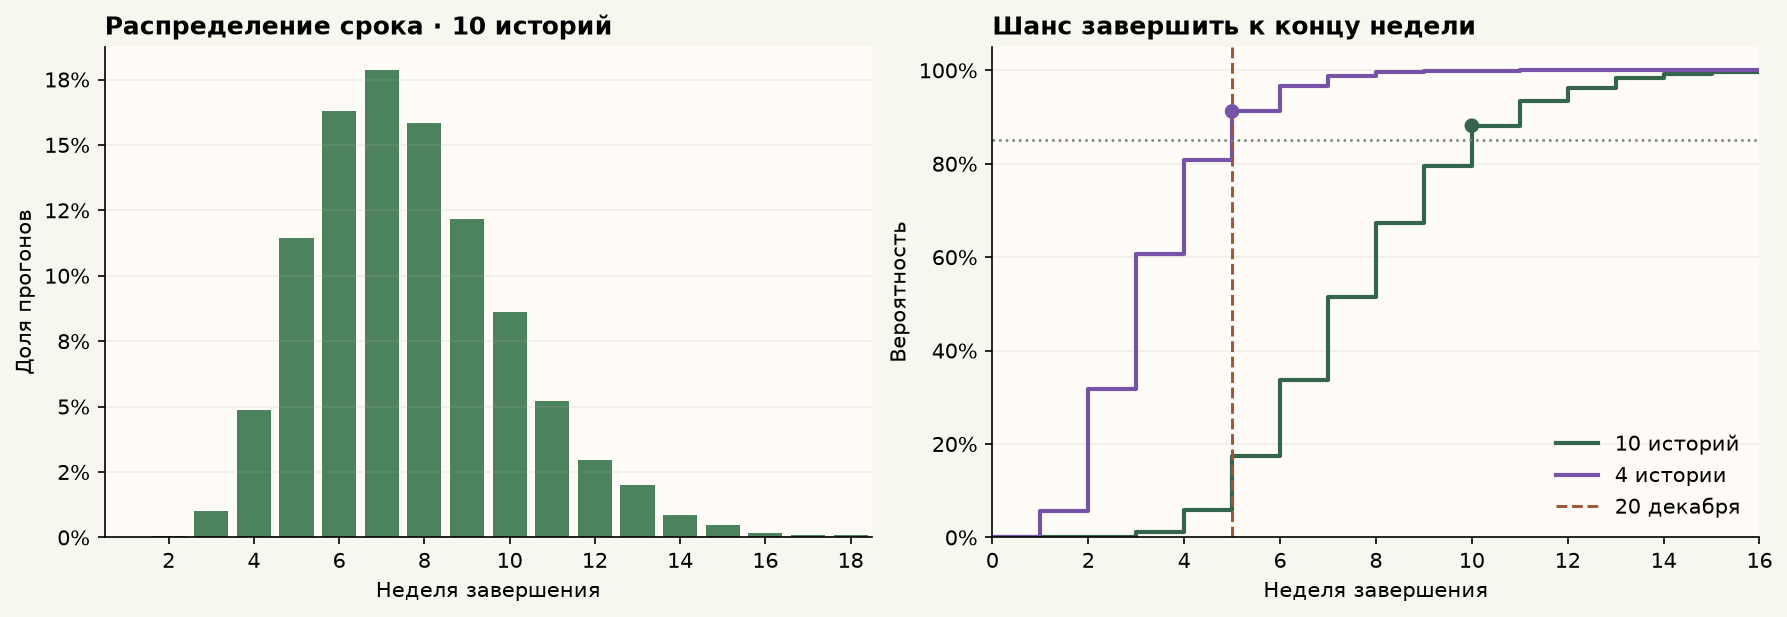

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

base = scenarios["Соло 0,70, 10"]
pilot = scenarios["Соло 0,70, 4"]
fig, (hist_ax, cdf_ax) = plt.subplots(1, 2, figsize=(11.8, 4), layout="constrained")
fig.patch.set_facecolor("#f7f6ef")
for ax in (hist_ax, cdf_ax):
    ax.set_facecolor("#fffcf7")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.18)
    ax.set_xlabel("Неделя завершения")

counts = Counter(base)
weeks = range(1, max(base) + 1)
hist_ax.bar(weeks, [counts[w] / TRIALS for w in weeks], color="#4c835e", width=.8)
hist_ax.set_title("Распределение срока · 10 историй", loc="left", fontweight="bold")
hist_ax.set_ylabel("Доля прогонов")
hist_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
hist_ax.set_xlim(.5, 18.5)

for values, label, mark in [(base, "10 историй", "#35664b"), (pilot, "4 истории", "#7653a7")]:
    x = list(range(0, max(base) + 1))
    cdf_ax.step(x, [probability_by(values, w) for w in x], where="post", lw=2, label=label, color=mark)
cdf_ax.axvline(review_week, color="#a35436", linestyle="--", lw=1.4, label="20 декабря")
cdf_ax.axhline(.85, color="#718175", linestyle=":", lw=1.2)
cdf_ax.scatter([5, 10], [probability_by(pilot, 5), probability_by(base, 10)], color=["#7653a7", "#35664b"], zorder=5)
cdf_ax.set_title("Шанс завершить к концу недели", loc="left", fontweight="bold")
cdf_ax.set_ylabel("Вероятность")
cdf_ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
cdf_ax.set_xlim(0, 16)
cdf_ax.set_ylim(0, 1.05)
cdf_ax.legend(loc="lower right", frameon=False)
plt.show()

## Интерпретация
Сентябрьский план оставляет после 15 ноября пять недель. К 20 декабря укладываются 91,21% прогонов с четырьмя историями, 82,37% с пятью, 39,97% с восемью и 17,35% с десятью. P85 для четырёх историй приходится на 20 декабря. Их 22 часа укладываются в плановые 26 часов. Срок занятия зависит от языковой вычитки и согласия группы. После двух недель фактических закрытий оценка пересматривается.